# Hands-on 1 — Setup and your first embeddings

**Chapter 3 · Where and how to access embeddings**

In this notebook you will:

1. check that your Python environment works,
2. locate the AlphaEarth Satellite Embedding tiles that cover a study area, using Google's official tile index,
3. read a 10 km × 11 km window of 64-dimensional embeddings straight from the public cloud bucket (no account needed),
4. undo the 8-bit quantization and check the vectors are unit length,
5. turn 64 numbers per pixel into a picture with PCA,
6. compare a few pixels with cosine similarity,
7. save the data for the next notebooks.

**Study area.** East Attica, Greece: the Penteli mountain forest in the west, the towns of Nea Makri and Rafina on the coast, farmland in between, and the area burned by the Mati wildfire of 23 July 2018. We will keep using this area, so what you learn here about its embeddings carries over.

Expected run time: about 2 minutes, with roughly 70 MB downloaded.

## 0. Check the environment

Run this cell first. It imports everything the notebook needs and prints versions. If it fails, go back to `SETUP.md`.

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio, duckdb, sklearn, folium

import eoemb  # small helper library shipped with the course (notebooks/eoemb.py)

print(f"python {sys.version.split()[0]} · numpy {np.__version__} · rasterio {rasterio.__version__} · "
      f"duckdb {duckdb.__version__} · scikit-learn {sklearn.__version__} · folium {folium.__version__}")

python 3.11.15 · numpy 2.4.6 · rasterio 1.4.4 · duckdb 1.5.5 · scikit-learn 1.9.0 · folium 0.20.0


## 1. The study area

Bounding boxes in this course are always `(west, south, east, north)` in degrees (EPSG:4326).

In [2]:
AOI = (23.90, 38.00, 24.00, 38.10)  # East Attica: Penteli – Nea Makri – Mati – Rafina

m = folium.Map(location=[(AOI[1] + AOI[3]) / 2, (AOI[0] + AOI[2]) / 2], zoom_start=12, tiles="OpenStreetMap")
folium.Rectangle([[AOI[1], AOI[0]], [AOI[3], AOI[2]]], color="red", fill=False, weight=2).add_to(m)
m

## 2. Find the right tiles with the official index

The AlphaEarth annual embeddings live in a public Google Cloud Storage bucket as Cloud Optimized GeoTIFFs (COGs):

```
gs://alphaearth_foundations/satellite_embedding/v1/annual/<year>/<utm_zone>/<image_id>-<row_offset>-<col_offset>.tiff
```

There are about 300 000 files (9 years × 120 UTM zones × several hundred tiles each). Nobody browses that by hand: Google publishes an index (`aef_index.parquet`) with the footprint of every file. The course ships the rows for Greece (`data/aef_index_greece.parquet`, 35 KB). The helper below reads it with DuckDB.

In [3]:
index = eoemb.load_aef_index()
print(f"{len(index)} tiles for Greece, years {index.year.min()}–{index.year.max()}")
index.head(3)

1188 tiles for Greece, years 2017–2025


,path,year,utm_zone,crs,utm_west,utm_south,utm_east,utm_north,wgs84_west,wgs84_south,wgs84_east,wgs84_north
0,gs://alphaearth_foundations/satellite_embeddin...,2017,34N,EPSG:32634,336160.0,3932160.0,418080.0,4014080.0,19.176273,35.519524,20.096414,36.268181
1,gs://alphaearth_foundations/satellite_embeddin...,2017,34N,EPSG:32634,418080.0,3932160.0,500000.0,4014080.0,20.087980,35.529675,21.000000,36.271658
2,gs://alphaearth_foundations/satellite_embeddin...,2017,34N,EPSG:32634,336160.0,4014080.0,418080.0,4096000.0,19.158793,36.257752,20.087980,37.006593


In [4]:
tiles_2024 = eoemb.aef_tiles_for(index, AOI, year=2024)
tiles_2024[["path", "utm_zone", "crs", "wgs84_west", "wgs84_south", "wgs84_east", "wgs84_north"]]

,path,utm_zone,crs,wgs84_west,wgs84_south,wgs84_east,wgs84_north
977,gs://alphaearth_foundations/satellite_embeddin...,34N,EPSG:32634,23.78816,37.710387,24.0,38.453035


One tile, in UTM zone 34N, covers the whole area for 2024. Two things worth noticing in the file name:

- `xmc2wlvtjehg2if5c` is the id of the Earth Engine image this file belongs to (`GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL/xmc2wlvtjehg2if5c`). If you ever move to Earth Engine, that is the link.
- `0000008192-0000008192` is the pixel offset of this COG inside that 16384 × 16384 image. Each Earth Engine image is split into four 8192 × 8192 COGs so no file exceeds ~300 MB.

**Anywhere else on Earth?** Query the full index directly from the bucket. DuckDB fetches only the parts of the 70 MB file it needs:

```python
world = eoemb.load_aef_index(eoemb.AEF_INDEX_URL, bbox=(-9.3, 38.6, -9.0, 38.9))  # Lisbon
```

## 3. Read the embeddings for the study area

`aef_read_bbox` opens the tile over HTTPS with rasterio and reads only the pixels inside the bounding box. The GDAL settings in `eoemb.GDAL_REMOTE_OPTS` matter: with them the read takes seconds, without them minutes, because GDAL otherwise fetches the 64 bands one small block at a time.

In [5]:
t0 = time.time()
raw, transform, crs = eoemb.aef_read_bbox(AOI, year=2024, index=index)
print(f"array {raw.shape} {raw.dtype}  →  {raw.nbytes / 1e6:.0f} MB in memory, read in {time.time() - t0:.1f} s")
print("CRS:", crs)
print("pixel size:", transform.a, "m")
print("upper-left corner (UTM):", transform.c, transform.f)

array (64, 1138, 913) int8  →  66 MB in memory, read in 7.4 s
CRS: EPSG:32634
pixel size: 10.0 m
upper-left corner (UTM): 754290.0 4221160.0


The array is `(bands, rows, cols)`: 64 embedding axes named A00…A63, 1138 rows, 913 columns of 10 m pixels. That is about one million locations, each described by 64 numbers.

## 4. From stored bytes to vectors

Each value is a **signed 8-bit integer** (-127…127). That is a storage trick: one byte per axis instead of four for a float, which is what makes a global product of this size shippable. The value **-128 is reserved for "no data"**.

To get the real embedding value in [-1, 1], the documentation says: divide by 127.5, square, keep the sign. `eoemb.dequantize` does exactly that and turns nodata into NaN.

In [6]:
row, col = 600, 450  # some pixel in the middle
print("stored int8 values of one pixel:")
print(raw[:, row, col])

emb = eoemb.dequantize(raw)
print("\nafter de-quantization:")
print(np.round(emb[:, row, col], 3))
print("\nvector length (should be 1):", np.linalg.norm(emb[:, row, col]).round(4))

stored int8 values of one pixel:
[ 42  45  18 -43  29  34  47 -10 -15 -46 -24 -27 -64 -40 -15 -26 -35  36
 -30  54  28  37 -20  50 -22  34 -46  40  68  41  75  10  68  48 -43  44
 -47 -35 -49  62  27 -36  23 -55  35  39  25 -40 -61 -28 -33  37 -22 -50
  28 -65  19  32 -23 -43 -23 -44 -40 -39]

after de-quantization:
[ 0.109  0.125  0.02  -0.114  0.052  0.071  0.136 -0.006 -0.014 -0.13
 -0.035 -0.045 -0.252 -0.098 -0.014 -0.042 -0.075  0.08  -0.055  0.179
  0.048  0.084 -0.025  0.154 -0.03   0.071 -0.13   0.098  0.284  0.103
  0.346  0.006  0.284  0.142 -0.114  0.119 -0.136 -0.075 -0.148  0.236
  0.045 -0.08   0.033 -0.186  0.075  0.094  0.038 -0.098 -0.229 -0.048
 -0.067  0.084 -0.03  -0.154  0.048 -0.26   0.022  0.063 -0.033 -0.114
 -0.033 -0.119 -0.098 -0.094]

vector length (should be 1): 0.9999


Every AlphaEarth embedding is normalised to **unit length**. Two consequences you will use again and again:

- the embedding says nothing about "how much" of something there is, only about *what kind* of place it is: all the information is in the direction of the vector;
- the cosine similarity between two pixels is simply their dot product.

norm  min/median/max: 0.991 1.0 1.009


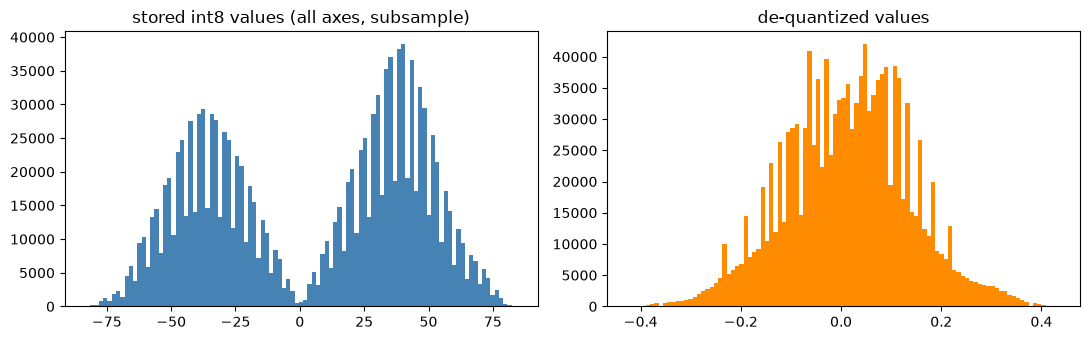

In [7]:
norms = np.linalg.norm(emb, axis=0)
print("norm  min/median/max:", np.nanmin(norms).round(3), np.nanmedian(norms).round(3), np.nanmax(norms).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(raw[raw != eoemb.AEF_NODATA].ravel()[::50], bins=101, color="steelblue")
ax[0].set_title("stored int8 values (all axes, subsample)")
ax[1].hist(emb[:, ~np.isnan(emb[0])].ravel()[::50], bins=101, color="darkorange")
ax[1].set_title("de-quantized values")
plt.tight_layout()

The squaring step gives the float values a strong peak around zero: most axes contribute little to most pixels, and a few axes carry the signal. This is a deliberate design choice that makes the 8-bit storage lose very little information.

## 5. No-data pixels

Let us see where the NaNs are.

1.1% of pixels have no data


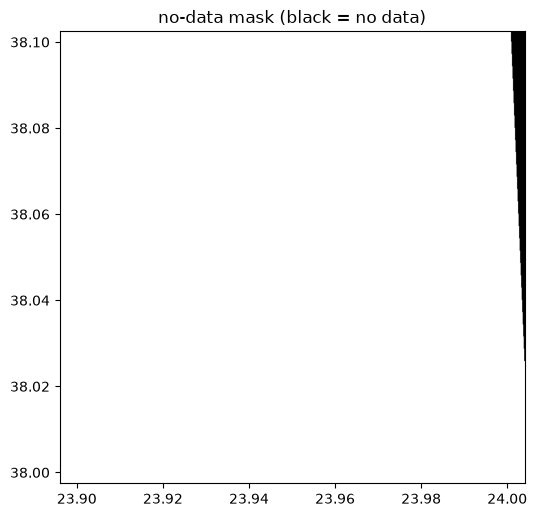

In [8]:
nodata = np.isnan(emb[0])
extent = eoemb.lonlat_extent(transform, crs, raw.shape[1:])
print(f"{nodata.mean() * 100:.1f}% of pixels have no data")

plt.figure(figsize=(6, 6))
plt.imshow(nodata, extent=extent, cmap="gray_r")
plt.title("no-data mask (black = no data)");

The wedge on the east edge is the 24° E meridian: the border between UTM zones 34 and 35. AlphaEarth tiles stop at their zone boundary, and a meridian is a slightly slanted line in a UTM grid, hence the wedge. The pixels east of it live in the zone 35N tiles (the index lists them). Two lessons: **check the nodata mask** whenever you cut a window near 18°, 24° or 30° E in Greece, and prefer study areas that do not straddle a zone boundary. Everything in this notebook treats NaN correctly, so we simply carry on.

## 6. The first picture: 64 dimensions → 3 colours

Nobody can look at 64 bands. The standard trick is **principal component analysis (PCA)**: find the three directions in the 64-dimensional space along which the pixels vary most, and map them to red, green and blue. Pixels that look alike in the embedding space get similar colours.

PCA done in 0.2 s


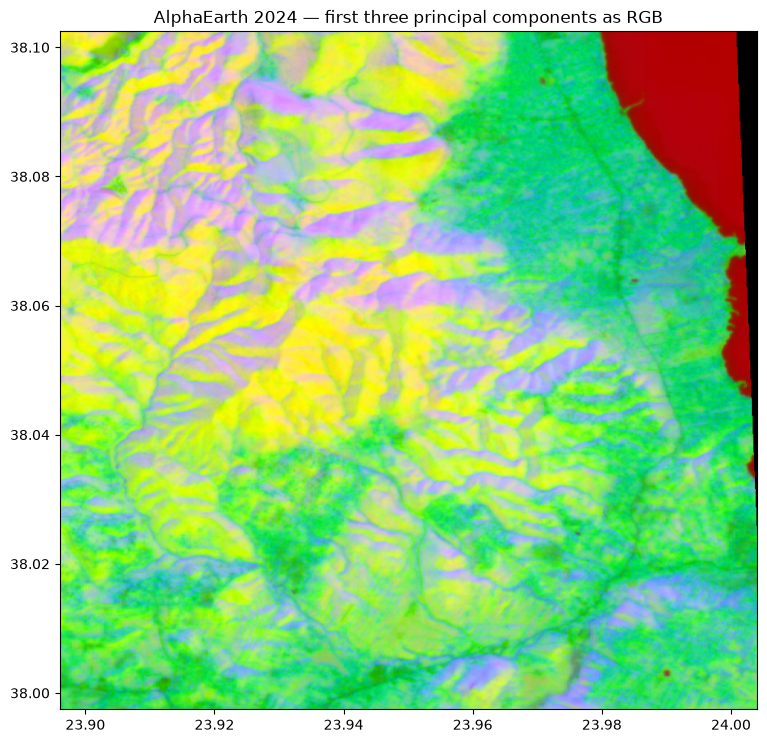

In [9]:
t0 = time.time()
rgb = eoemb.pca_rgb(emb)
print(f"PCA done in {time.time() - t0:.1f} s")

plt.figure(figsize=(9, 9))
plt.imshow(rgb, extent=extent)
plt.title("AlphaEarth 2024 — first three principal components as RGB");

Read this image with care. The colours have no fixed meaning: they are whatever three directions explain most of the variance *in this particular window*. Here the strongest signals are the sea against the land and, on land, the topography of Penteli (AlphaEarth is trained with elevation and radar as inputs, so relief and aspect leave a strong imprint). Land-cover differences are in there too, but they are not what the first three components pick up in a hilly area.

Excluding the sea before fitting the PCA gives the land more of the colour budget:

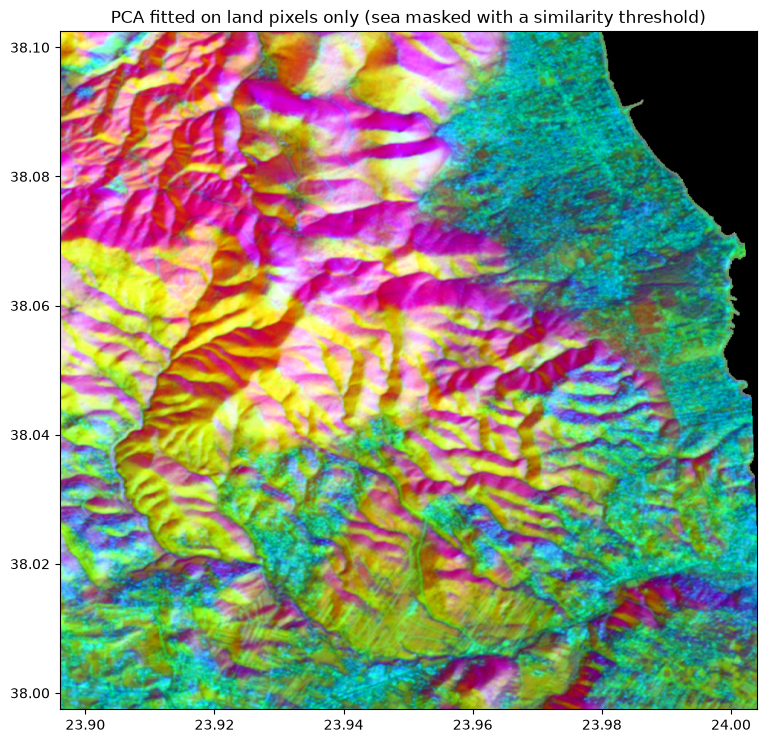

In [10]:
sea_ref = eoemb.sample(emb, *eoemb.lonlat_to_rowcol([23.995], [38.09], transform, crs))[0]
sea_like = eoemb.cosine_similarity_map(emb, sea_ref) > 0.9

emb_land = emb.copy()
emb_land[:, sea_like] = np.nan
rgb_land = eoemb.pca_rgb(emb_land)

plt.figure(figsize=(9, 9))
plt.imshow(rgb_land, extent=extent)
plt.title("PCA fitted on land pixels only (sea masked with a similarity threshold)");

Notice what just happened: we removed the sea **without a water index, without a threshold on any band**. We took one pixel we knew was sea and kept every pixel whose embedding points in nearly the same direction (cosine similarity above 0.9). That is the basic move of working with embeddings, and Hands-on 3 is built entirely on it.

## 7. Comparing places with cosine similarity

Four reference points, chosen on a map: forest on Penteli, the town centre of Nea Makri, the area burned in 2018, and the sea.

In [11]:
points = pd.DataFrame({
    "name": ["forest", "town", "burned 2018", "sea"],
    "lon": [23.935, 23.9765, 23.985, 23.995],
    "lat": [38.085, 38.0855, 38.045, 38.09],
})
rows, cols = eoemb.lonlat_to_rowcol(points.lon, points.lat, transform, crs)
vectors = eoemb.sample(emb, rows, cols)  # (4, 64)

sim = vectors @ vectors.T  # unit vectors: dot product = cosine similarity
pd.DataFrame(sim, index=points.name, columns=points.name).round(2)

name,forest,town,burned 2018,sea
name,,,,
forest,1.00,0.65,0.65,0.26
town,0.65,1.01,0.74,0.11
burned 2018,0.65,0.74,1.01,0.12
sea,0.26,0.11,0.12,1.00


The diagonal is 1 (a place is identical to itself; 1.01 is rounding from the 8-bit storage). The sea is unlike everything on land (0.1 to 0.3). Forest and town are clearly different (0.65). The area burned in 2018 is most similar to the town (0.74): Mati was a residential area and has been rebuilt, and six years of regrowth have hidden most of the fire signal in a 2024 embedding. Whether an embedding can still see that fire is a question for Hands-on 5. These numbers are the whole basis of similarity search, clustering and classification in Chapter 4.

## 8. On a web map

A false-colour PCA image is much easier to interpret over a base map.


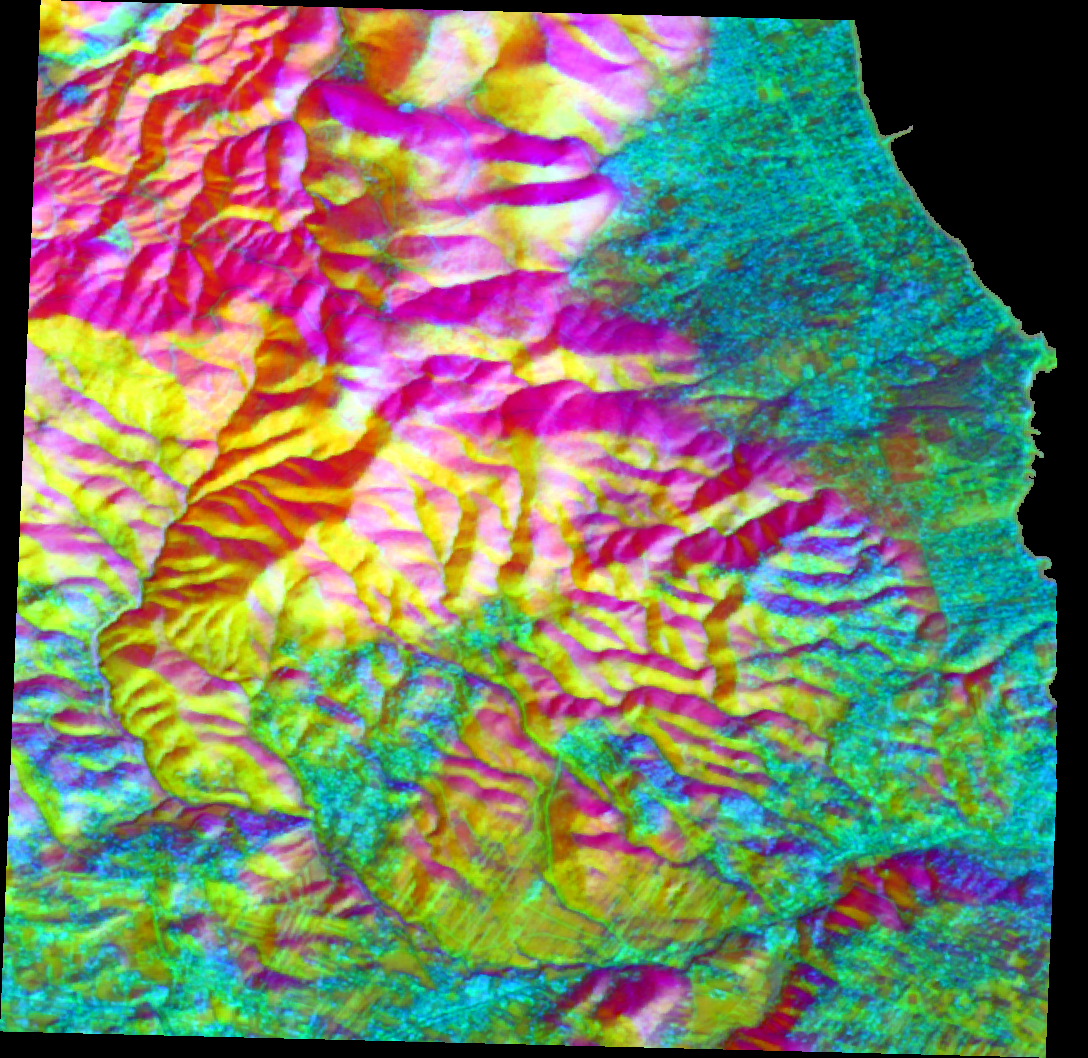

In [12]:
overlay, bounds = eoemb.to_lonlat_image(rgb_land, transform, crs)

m = folium.Map(location=[(AOI[1] + AOI[3]) / 2, (AOI[0] + AOI[2]) / 2], zoom_start=12, tiles="OpenStreetMap")
folium.raster_layers.ImageOverlay(overlay, bounds=bounds, opacity=0.7, name="AlphaEarth PCA 2024").add_to(m)
for _, p in points.iterrows():
    folium.CircleMarker([p.lat, p.lon], radius=6, color="black", fill=True, fill_color="white", popup=p["name"]).add_to(m)
folium.LayerControl().add_to(m)
m

## 9. Save for the next notebooks

Reading takes seconds, but we will use this exact array in Hands-on 2 to 5, so store it once. We keep the raw int8 (small) plus the georeferencing, and also write a GeoTIFF you can open in QGIS.

In [13]:
cache = eoemb.DATA_DIR / "cache"
cache.mkdir(exist_ok=True)

np.savez_compressed(cache / "aef_attica_2024.npz", raw=raw, transform=np.array(transform.to_gdal()), crs=str(crs))

with rasterio.open(cache / "aef_attica_2024.tif", "w", driver="GTiff", height=raw.shape[1], width=raw.shape[2],
                   count=64, dtype="int8", crs=crs, transform=transform, nodata=eoemb.AEF_NODATA,
                   compress="zstd", tiled=True) as dst:
    dst.write(raw)
    dst.descriptions = tuple(f"A{i:02d}" for i in range(64))

print(sorted(p.name for p in cache.glob("aef_attica_2024.*")))

['aef_attica_2024.npz', 'aef_attica_2024.tif']


---
## Exercises

**E1.** Read the 2019 embeddings for the same area and show the PCA image next to 2024. Are the colours comparable between years? (Think about what PCA does before you answer.)

**E2.** Pick a place you know in Greece, define a 0.1° × 0.1° bounding box that does not cross a UTM zone boundary (zone borders are at 18°, 24° and 30° E), find its tiles in the index and read the 2024 embeddings. How much nodata do you get?

**E3.** Add a fifth reference point of your choice (farmland, a beach, a quarry…) to the similarity table. Which of the four references is it closest to?

Text(0.5, 1.0, '2024')

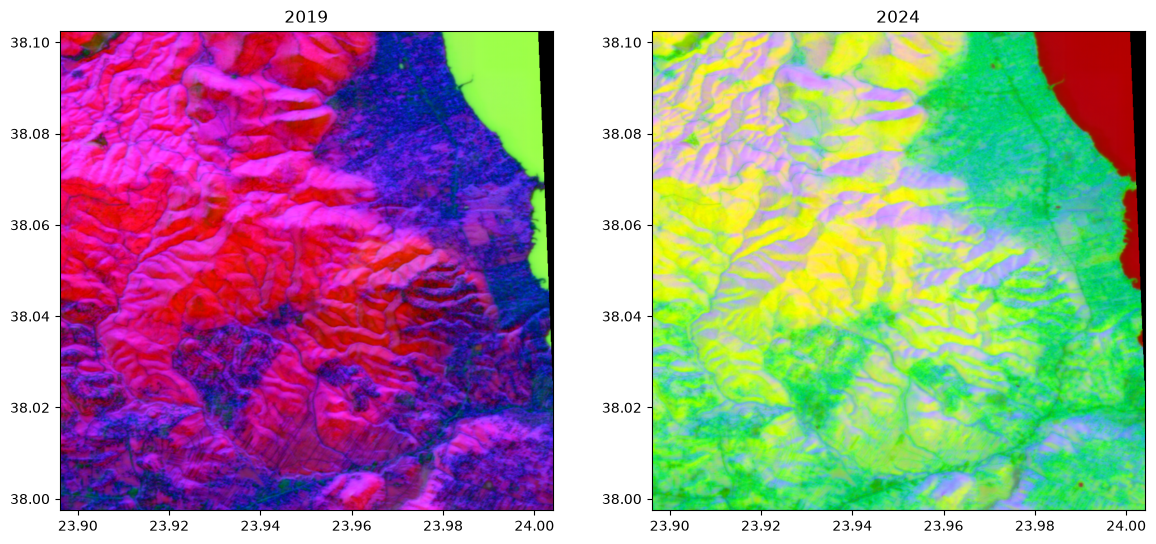

In [14]:
# --- Solution E1 ---
raw19, tr19, crs19 = eoemb.aef_read_bbox(AOI, year=2019, index=index)
rgb19 = eoemb.pca_rgb(eoemb.dequantize(raw19))
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(rgb19, extent=extent); ax[0].set_title("2019")
ax[1].imshow(rgb, extent=extent); ax[1].set_title("2024")
# Colours are NOT comparable: each PCA is fitted separately, so the axes (and even their sign) can differ.
# To compare years visually, fit one PCA on both years stacked and apply it to each.

(64, 1129, 886) EPSG:32634 nodata 0.0%


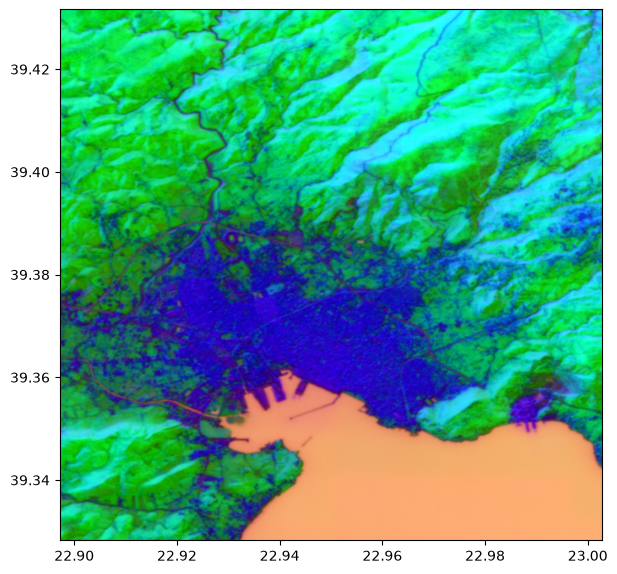

In [15]:
# --- Solution E2 (example: Volos, Thessaly) ---
aoi2 = (22.90, 39.33, 23.00, 39.43)
raw2, tr2, crs2 = eoemb.aef_read_bbox(aoi2, year=2024, index=index)
print(raw2.shape, crs2, f"nodata {np.mean(raw2[0] == eoemb.AEF_NODATA) * 100:.1f}%")
plt.figure(figsize=(7, 7)); plt.imshow(eoemb.pca_rgb(eoemb.dequantize(raw2)), extent=eoemb.lonlat_extent(tr2, crs2, raw2.shape[1:]));

In [16]:
# --- Solution E3 (example: fields on the coastal plain south of Nea Makri) ---
extra = pd.DataFrame({"name": ["fields"], "lon": [23.96], "lat": [38.005]})
pts = pd.concat([points, extra], ignore_index=True)
r, c = eoemb.lonlat_to_rowcol(pts.lon, pts.lat, transform, crs)
v = eoemb.sample(emb, r, c)
pd.DataFrame(v @ v.T, index=pts.name, columns=pts.name).round(2)

name,forest,town,burned 2018,sea,fields
name,,,,,
forest,1.00,0.65,0.65,0.26,0.66
town,0.65,1.01,0.74,0.11,0.44
burned 2018,0.65,0.74,1.01,0.12,0.45
sea,0.26,0.11,0.12,1.00,0.28
fields,0.66,0.44,0.45,0.28,1.01
